In [9]:

# ============================================================
# URFD DATASET FIX
# Download RGB ZIP sequences -> Extract PNG -> Create MP4
# ============================================================

import os
import re
import glob
import zipfile
import requests
import cv2
import numpy as np

from tqdm.auto import tqdm

BASE_DIR = "/content/URFD"
ZIP_DIR = BASE_DIR + "/zips"
FRAME_DIR = BASE_DIR + "/frames"
VIDEO_DIR = BASE_DIR + "/RGB"

for folder in [ZIP_DIR, FRAME_DIR, VIDEO_DIR]:
    os.makedirs(folder, exist_ok=True)

BASE_URL = "https://fenix.ur.edu.pl/~mkepski/ds/data/"

session = requests.Session()

# Natural sorting of frame filenames
def natural_sort(files):
    return sorted(
        files,
        key=lambda x: [
            int(t) if t.isdigit() else t.lower()
            for t in re.split(r'(\d+)', x)
        ]
    )

# ------------------------------------------------------------
# 1. DOWNLOAD 30 FALL + 40 ADL RGB ARCHIVES
# ------------------------------------------------------------

sequences = (
    [f"fall-{i:02d}" for i in range(1, 31)] +
    [f"adl-{i:02d}" for i in range(1, 41)]
)

for seq in tqdm(sequences, desc="Downloading URFD"):

    filename = seq + "-cam0-rgb.zip"

    zip_path = os.path.join(ZIP_DIR, filename)

    if os.path.exists(zip_path) and zipfile.is_zipfile(zip_path):
        continue

    url = BASE_URL + filename

    try:
        response = session.get(
            url,
            stream=True,
            timeout=180
        )

        response.raise_for_status()

        with open(zip_path, "wb") as f:
            for chunk in response.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)

        if not zipfile.is_zipfile(zip_path):
            os.remove(zip_path)
            print("Invalid ZIP:", filename)

    except Exception as e:
        print("Download failed:", filename, str(e)[:100])

# ------------------------------------------------------------
# 2. EXTRACT PNG FRAMES
# ------------------------------------------------------------

for seq in tqdm(sequences, desc="Extracting frames"):

    zip_path = os.path.join(
        ZIP_DIR, seq + "-cam0-rgb.zip"
    )

    output_dir = os.path.join(FRAME_DIR, seq)

    if not os.path.exists(zip_path):
        print("Missing archive:", seq)
        continue

    os.makedirs(output_dir, exist_ok=True)

    if len(glob.glob(output_dir + "/**/*.png", recursive=True)) > 0:
        continue

    try:
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(output_dir)

    except Exception as e:
        print("Extraction error:", seq, e)

# ------------------------------------------------------------
# 3. CONVERT PNG SEQUENCES INTO MP4 VIDEOS
# ------------------------------------------------------------

video_files = []

for seq in tqdm(sequences, desc="Creating videos"):

    input_dir = os.path.join(FRAME_DIR, seq)

    output_video = os.path.join(
        VIDEO_DIR, seq + ".mp4"
    )

    if os.path.exists(output_video) and os.path.getsize(output_video) > 1000:
        video_files.append(output_video)
        continue

    images = glob.glob(
        input_dir + "/**/*.png",
        recursive=True
    )

    images = natural_sort(images)

    if len(images) == 0:
        print("No PNG frames:", seq)
        continue

    first = cv2.imread(images[0])

    if first is None:
        print("Unreadable first frame:", seq)
        continue

    height, width = first.shape[:2]

    writer = cv2.VideoWriter(
        output_video,
        cv2.VideoWriter_fourcc(*"mp4v"),
        15,
        (width, height)
    )

    if not writer.isOpened():
        print("Could not create video:", seq)
        continue

    frame_count = 0

    for image_path in images:

        frame = cv2.imread(image_path)

        if frame is None:
            continue

        if frame.shape[:2] != (height, width):
            frame = cv2.resize(frame, (width, height))

        writer.write(frame)
        frame_count += 1

    writer.release()

    if frame_count > 0:
        video_files.append(output_video)
    else:
        print("No readable frames:", seq)

# ------------------------------------------------------------
# 4. CREATE VIDEO FILE LIST
# ------------------------------------------------------------

video_files = sorted(set(video_files))

print("\n================================")
print("URFD DATASET READY")
print("================================")

print("Total videos:", len(video_files))
print("Fall videos:", sum("fall-" in x.lower() for x in video_files))
print("ADL videos:", sum("adl-" in x.lower() for x in video_files))

for video in video_files[:10]:
    print(video)

if len(video_files) == 0:
    raise RuntimeError(
        "No videos were generated. Check download errors and ZIP files."
    )

print("\nYou can now continue with the labeling section.")


Extracting frames:   0%|          | 0/70 [00:00<?, ?it/s]

Creating videos:   0%|          | 0/70 [00:00<?, ?it/s]


URFD DATASET READY
Total videos: 70
Fall videos: 30
ADL videos: 40
/content/URFD/RGB/adl-01.mp4
/content/URFD/RGB/adl-02.mp4
/content/URFD/RGB/adl-03.mp4
/content/URFD/RGB/adl-04.mp4
/content/URFD/RGB/adl-05.mp4
/content/URFD/RGB/adl-06.mp4
/content/URFD/RGB/adl-07.mp4
/content/URFD/RGB/adl-08.mp4
/content/URFD/RGB/adl-09.mp4
/content/URFD/RGB/adl-10.mp4

You can now continue with the labeling section.


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

DATASET INFORMATION
-------------------
Total videos: 70
Fall videos: 30
ADL videos: 40


Verifying videos:   0%|          | 0/70 [00:00<?, ?it/s]


Verified videos: 70
Fall: 30
ADL: 40


,Video,Label,Class
0,/content/URFD/RGB/adl-01.mp4,0,ADL
1,/content/URFD/RGB/adl-02.mp4,0,ADL
2,/content/URFD/RGB/adl-03.mp4,0,ADL
3,/content/URFD/RGB/adl-04.mp4,0,ADL
4,/content/URFD/RGB/adl-05.mp4,0,ADL


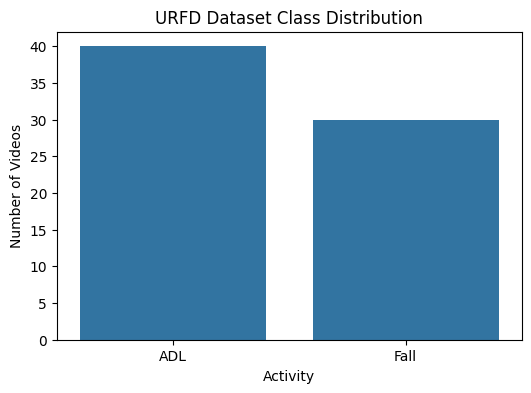

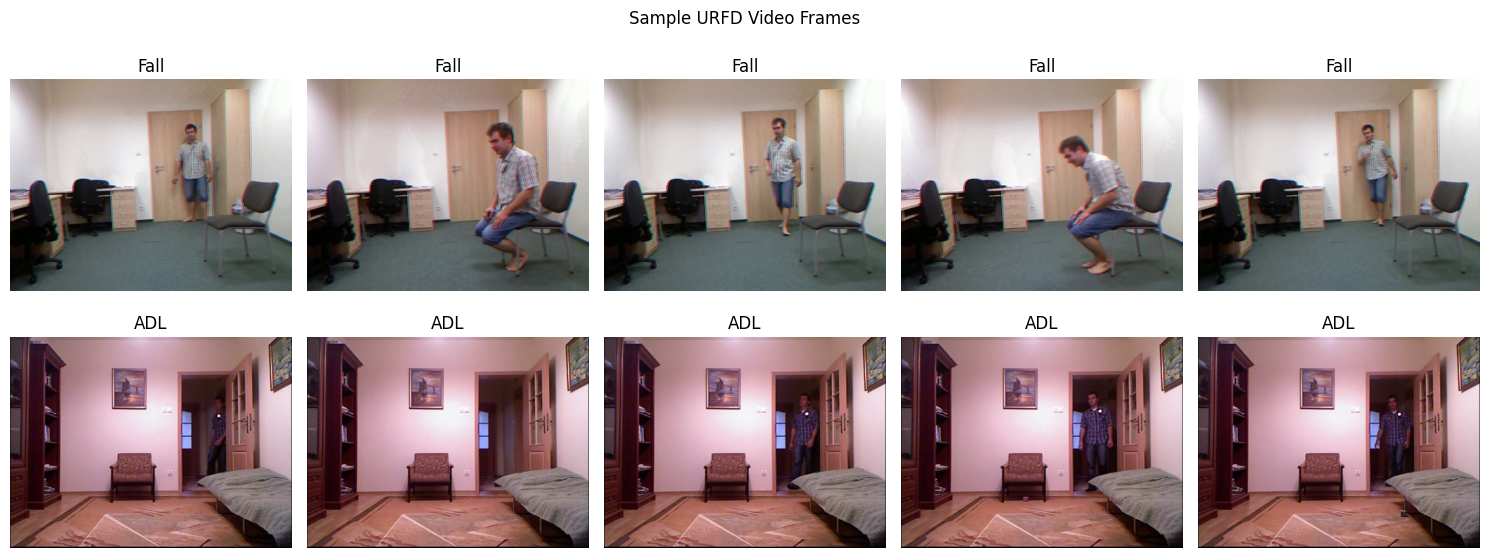


DATA SPLIT
Training: 49
Validation: 10
Testing: 11

Sample video tensor shape: (16, 112, 112, 3)
Pixel range: 0.0 1.0

Training batches: 25
Validation batches: 5
Testing batches: 6

Class weights: {0: 0.875, 1: 1.1666666666666667}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 112, 112,   │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 56, 56, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 28, 28, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 4, 14, 14, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 14, 14, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 2, 7, 7, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 309,441 (1.18 MB)

 Trainable params: 308,961 (1.18 MB)

 Non-trainable params: 480 (1.88 KB)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.4694 - auc: 0.5170 - loss: 0.9521 - precision: 0.4138 - recall: 0.5714 - val_accuracy: 0.4000 - val_auc: 0.8333 - val_loss: 0.7156 - val_precision: 0.4000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 16s 645ms/step - accuracy: 0.6735 - auc: 0.7866 - loss: 0.6356 - precision: 0.6087 - recall: 0.6667 - val_accuracy: 0.4000 - val_auc: 0.8750 - val_loss: 0.7420 - val_precision: 0.4000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 660ms/step - accuracy: 0.7959 - auc: 0.8367 - loss: 0.5781 - precision: 0.7200 - recall: 0.8571 - val_accuracy: 0.4000 - val_auc: 0.7708 - val_loss: 0.7622 - val_precision: 0.4000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 16s 637ms/step - accuracy: 0.7143 - auc: 0.8265 - loss: 0.5131 - precision: 0.6400 - recall: 0.7619 - val_accuracy: 0.4000 - val_auc: 0.9167 - val_loss:

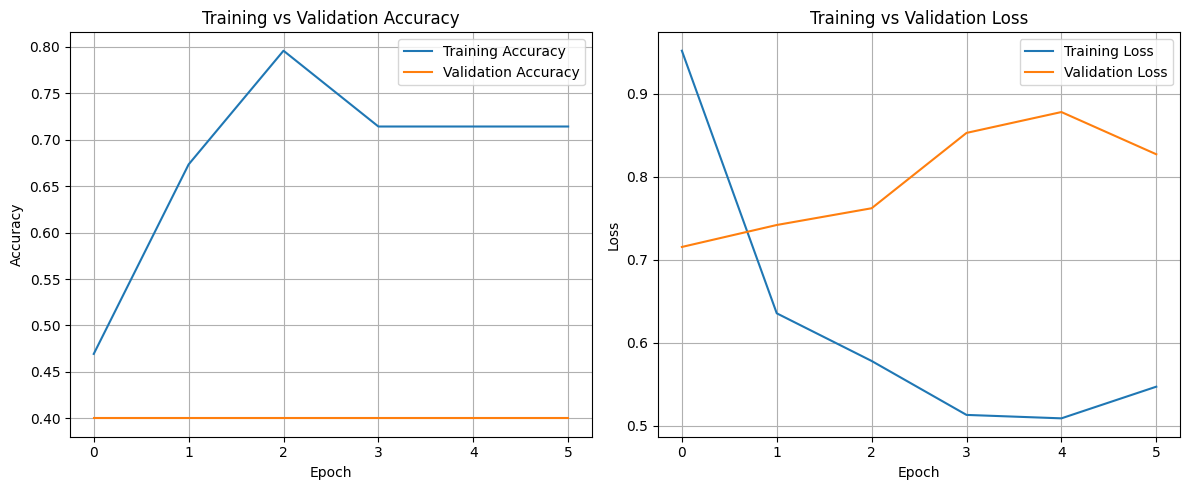

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 520ms/step

Predictions: 11
Actual labels: 11

3D CNN FALL DETECTION RESULTS
Accuracy  : 0.4545
Precision : 0.4545
Recall    : 1.0000
F1 Score  : 0.6250
AUROC     : 0.8000

Classification Report:
              precision    recall  f1-score   support

         ADL       0.00      0.00      0.00         6
        Fall       0.45      1.00      0.62         5

    accuracy                           0.45        11
   macro avg       0.23      0.50      0.31        11
weighted avg       0.21      0.45      0.28        11



,Metric,Value
0,Accuracy,0.454545
1,Precision,0.454545
2,Recall,1.000000
3,F1 Score,0.625000
4,AUROC,0.800000


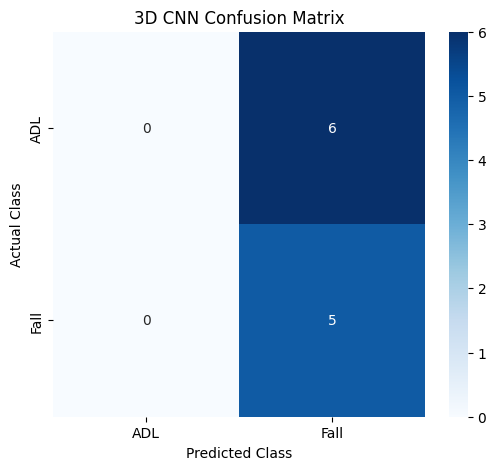

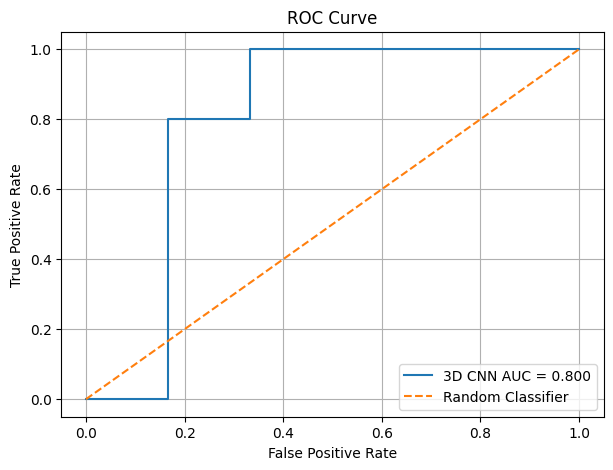


Misclassified videos: 6

Video: /content/URFD/RGB/adl-11.mp4
Actual: ADL
Predicted: Fall
Fall probability: 0.5601


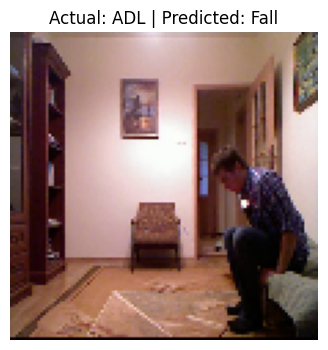


Video: /content/URFD/RGB/adl-29.mp4
Actual: ADL
Predicted: Fall
Fall probability: 0.5649


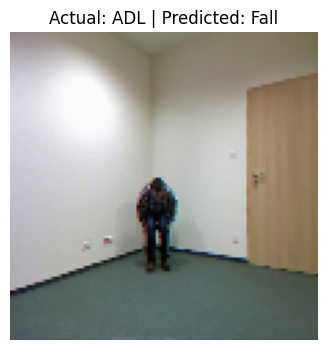


Video: /content/URFD/RGB/adl-15.mp4
Actual: ADL
Predicted: Fall
Fall probability: 0.542


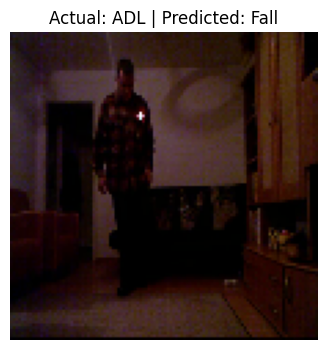


Video: /content/URFD/RGB/adl-33.mp4
Actual: ADL
Predicted: Fall
Fall probability: 0.5615


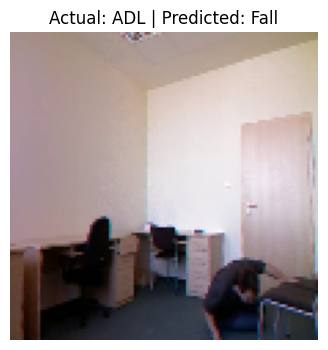


Video: /content/URFD/RGB/adl-23.mp4
Actual: ADL
Predicted: Fall
Fall probability: 0.5423


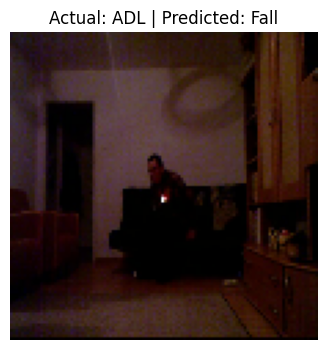


IMPLEMENTATION COMPLETED
Saved model:
/content/URFD/models/final_urfd_3dcnn_model.keras

Saved results:
/content/URFD/results

Final test accuracy: 45.45 %


In [10]:

# ============================================================
# URFD FALL DETECTION USING 3D CNN
# COMPLETE IMPLEMENTATION AFTER DATASET FIX
# Run this cell AFTER your URFD DATASET FIX cell
# ============================================================

# -------------------------------
# 1. IMPORT LIBRARIES
# -------------------------------

!pip -q install scikit-learn seaborn opencv-python-headless

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from tensorflow.keras.utils import Sequence

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


# ============================================================
# 2. CONFIGURATION
# ============================================================

NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112
CHANNELS = 3

BATCH_SIZE = 2
EPOCHS = 20
LEARNING_RATE = 0.0001

OUTPUT_DIR = "/content/URFD/results"
MODEL_DIR = "/content/URFD/models"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)


# ============================================================
# 3. DATASET LABELING
# ============================================================

def get_label(video_path):

    filename = os.path.basename(video_path).lower()

    if "fall-" in filename:
        return 1
    elif "adl-" in filename:
        return 0

    return None


video_files = sorted(set(video_files))

valid_data = [
    (video, get_label(video))
    for video in video_files
    if get_label(video) is not None
]

video_files = [x[0] for x in valid_data]
labels = np.array([x[1] for x in valid_data], dtype=np.int32)

print("\nDATASET INFORMATION")
print("-------------------")
print("Total videos:", len(video_files))
print("Fall videos:", np.sum(labels == 1))
print("ADL videos:", np.sum(labels == 0))

if len(video_files) < 10 or len(np.unique(labels)) != 2:
    raise RuntimeError("Insufficient videos or missing class. Check the dataset fix cell.")


# ============================================================
# 4. VERIFY VIDEO FILES
# ============================================================

verified_videos = []
verified_labels = []

for video, label in tqdm(
    zip(video_files, labels),
    total=len(video_files),
    desc="Verifying videos"
):

    cap = cv2.VideoCapture(video)

    if cap.isOpened():

        ret, frame = cap.read()

        if ret and frame is not None:
            verified_videos.append(video)
            verified_labels.append(label)

    cap.release()

video_files = verified_videos
labels = np.array(verified_labels, dtype=np.int32)

print("\nVerified videos:", len(video_files))
print("Fall:", np.sum(labels == 1))
print("ADL:", np.sum(labels == 0))

if len(video_files) < 10 or len(np.unique(labels)) != 2:
    raise RuntimeError("Not enough valid videos after verification.")


# ============================================================
# 5. DATASET SUMMARY AND VISUALIZATION
# ============================================================

dataset_df = pd.DataFrame({
    "Video": video_files,
    "Label": labels,
    "Class": [
        "Fall" if label == 1 else "ADL"
        for label in labels
    ]
})

display(dataset_df.head())

plt.figure(figsize=(6, 4))
sns.countplot(data=dataset_df, x="Class")
plt.title("URFD Dataset Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Videos")
plt.show()

# Show sample frames
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, class_label in enumerate([1, 0]):

    indices = np.where(labels == class_label)[0][:5]

    for col in range(5):

        axes[row, col].axis("off")

        if col >= len(indices):
            continue

        idx = indices[col]

        cap = cv2.VideoCapture(video_files[idx])
        cap.set(cv2.CAP_PROP_POS_FRAMES, 10)

        ret, frame = cap.read()
        cap.release()

        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            axes[row, col].imshow(frame)

        axes[row, col].set_title(
            "Fall" if class_label == 1 else "ADL"
        )

plt.suptitle("Sample URFD Video Frames")
plt.tight_layout()
plt.show()


# ============================================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X = np.array(video_files)
y = labels

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("\nDATA SPLIT")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


# ============================================================
# 7. VIDEO FRAME EXTRACTION AND PREPROCESSING
# ============================================================

def load_video(video_path, augment=False):

    cap = cv2.VideoCapture(video_path)

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        raise ValueError(f"Invalid video: {video_path}")

    indices = np.linspace(
        0,
        total_frames - 1,
        NUM_FRAMES
    ).astype(int)

    frames = []

    for idx in indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()

        if not ret or frame is None:
            frame = np.zeros(
                (IMG_HEIGHT, IMG_WIDTH, 3),
                dtype=np.uint8
            )

        else:

            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frame = cv2.resize(
                frame,
                (IMG_WIDTH, IMG_HEIGHT)
            )

        # Horizontal flip
        if augment and np.random.random() < 0.5:
            frame = cv2.flip(frame, 1)

        # Small rotation augmentation
        if augment and np.random.random() < 0.3:

            angle = np.random.uniform(-8, 8)

            matrix = cv2.getRotationMatrix2D(
                (IMG_WIDTH // 2, IMG_HEIGHT // 2),
                angle,
                1.0
            )

            frame = cv2.warpAffine(
                frame,
                matrix,
                (IMG_WIDTH, IMG_HEIGHT)
            )

        # Brightness augmentation
        if augment and np.random.random() < 0.3:

            brightness = np.random.uniform(0.85, 1.15)

            frame = np.clip(
                frame.astype(np.float32) * brightness,
                0,
                255
            ).astype(np.uint8)

        # Normalize to [0,1]
        frame = frame.astype(np.float32) / 255.0

        frames.append(frame)

    cap.release()

    return np.array(frames, dtype=np.float32)


sample_video = load_video(X_train[0])

print("\nSample video tensor shape:", sample_video.shape)
print("Pixel range:", sample_video.min(), sample_video.max())


# ============================================================
# 8. DATA GENERATOR
# ============================================================

class FallDetectionGenerator(Sequence):

    def __init__(
        self,
        names,
        labels,
        batch_size=2,
        augment=False,
        shuffle=False
    ):

        super().__init__()

        self.names = np.array(names)
        self.labels = np.array(labels)

        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle

        self.indices = np.arange(len(self.names))

        self.on_epoch_end()

    def __len__(self):

        return int(
            np.ceil(len(self.names) / self.batch_size)
        )

    def __getitem__(self, index):

        batch_indices = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch_x = []
        batch_y = []

        for i in batch_indices:

            video = load_video(
                self.names[i],
                augment=self.augment
            )

            batch_x.append(video)
            batch_y.append(self.labels[i])

        return (
            np.array(batch_x, dtype=np.float32),
            np.array(batch_y, dtype=np.float32)
        )

    def on_epoch_end(self):

        if self.shuffle:
            np.random.shuffle(self.indices)


train_generator = FallDetectionGenerator(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    augment=True,
    shuffle=True
)

val_generator = FallDetectionGenerator(
    X_val,
    y_val,
    batch_size=BATCH_SIZE
)

test_generator = FallDetectionGenerator(
    X_test,
    y_test,
    batch_size=BATCH_SIZE
)

print("\nTraining batches:", len(train_generator))
print("Validation batches:", len(val_generator))
print("Testing batches:", len(test_generator))


# ============================================================
# 9. HANDLE CLASS IMBALANCE
# ============================================================

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("\nClass weights:", class_weights)


# ============================================================
# 10. BUILD 3D CNN MODEL
# ============================================================

model = models.Sequential([

    layers.Input(
        shape=(
            NUM_FRAMES,
            IMG_HEIGHT,
            IMG_WIDTH,
            CHANNELS
        )
    ),

    layers.Conv3D(
        16,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling3D(
        pool_size=(1, 2, 2)
    ),

    layers.Conv3D(
        32,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling3D(
        pool_size=(2, 2, 2)
    ),

    layers.Conv3D(
        64,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling3D(
        pool_size=(2, 2, 2)
    ),

    layers.Conv3D(
        128,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling3D(
        pool_size=(2, 2, 2)
    ),

    layers.GlobalAveragePooling3D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        1,
        activation="sigmoid"
    )

])

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()


# ============================================================
# 11. TRAIN THE 3D CNN
# ============================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            MODEL_DIR,
            "best_urfd_3dcnn.keras"
        ),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)


# ============================================================
# 12. TRAINING AND VALIDATION GRAPHS
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


# ============================================================
# 13. TEST SET PREDICTIONS
# ============================================================

y_prob = model.predict(
    test_generator,
    verbose=1
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

y_true = y_test.astype(int)

print("\nPredictions:", len(y_pred))
print("Actual labels:", len(y_true))


# ============================================================
# 14. MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc = (
    roc_auc_score(y_true, y_prob)
    if len(np.unique(y_true)) == 2
    else float("nan")
)

print("\n====================================")
print("3D CNN FALL DETECTION RESULTS")
print("====================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUROC     : {auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["ADL", "Fall"],
        zero_division=0
    )
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUROC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

display(metrics_df)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "evaluation_metrics.csv"),
    index=False
)


# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ADL", "Fall"],
    yticklabels=["ADL", "Fall"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("3D CNN Confusion Matrix")
plt.show()


# ============================================================
# 16. ROC CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"3D CNN AUC = {auc:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()

else:
    print("ROC curve cannot be calculated: only one class in test set.")


# ============================================================
# 17. MISCLASSIFICATION ANALYSIS
# ============================================================

misclassified = np.where(y_true != y_pred)[0]

print("\nMisclassified videos:", len(misclassified))

for idx in misclassified[:5]:

    actual = "Fall" if y_true[idx] == 1 else "ADL"

    predicted = "Fall" if y_pred[idx] == 1 else "ADL"

    print("\nVideo:", X_test[idx])
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Fall probability:", round(float(y_prob[idx]), 4))

    video = load_video(X_test[idx])

    plt.figure(figsize=(4, 4))
    plt.imshow(video[NUM_FRAMES // 2])

    plt.title(
        f"Actual: {actual} | Predicted: {predicted}"
    )

    plt.axis("off")
    plt.show()


# ============================================================
# 18. SAVE MODEL AND RESULTS
# ============================================================

model.save(
    os.path.join(
        MODEL_DIR,
        "final_urfd_3dcnn_model.keras"
    )
)

prediction_df = pd.DataFrame({

    "Video": X_test,

    "Actual Label": y_true,

    "Predicted Label": y_pred,

    "Fall Probability": y_prob

})

prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "test_predictions.csv"
    ),
    index=False
)

dataset_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "dataset_summary.csv"
    ),
    index=False
)

print("\n====================================")
print("IMPLEMENTATION COMPLETED")
print("====================================")

print("Saved model:")
print(os.path.join(MODEL_DIR, "final_urfd_3dcnn_model.keras"))

print("\nSaved results:")
print(OUTPUT_DIR)

print("\nFinal test accuracy:", round(accuracy * 100, 2), "%")
